# PTM3D notebook 05: Europa seen from Earth, and a fit of thermal inertia

A telescope such as ALMA measures the thermal emission of Europa's whole disk. Comparing such a
measurement with a thermal model takes three steps. The model temperatures are taken at the moment
the light left Europa, the emission of each face is computed at the observing frequency, and the
emission is summed over the faces that Earth sees. This notebook goes through the three steps with
the model run of [tutorial 7](../07_observing_europa.md), and then fits thermal inertia and a band
emissivity to synthetic observations.

The observations in section 7 are **synthetic**. They are made from a simulation with a known
thermal inertia and emissivity, plus noise, so that the fit can be checked against the truth. No
telescope data are used anywhere in this notebook.

**Cost:** one simulation of about 15 seconds, then about a minute of calculation. Section 7 needs
the 16 short simulations of `examples/python/fit_europa_disk_tb.py`, which take 4 to 7 minutes and
are run from a terminal (the cell says how).

**Needs:** the Europa SPICE kernels (`python3 scripts/fetch_kernels.py --bodies europa`, 1.1 GB),
and scipy.

In [1]:
import csv
import sys
import warnings

import numpy as np
from ptm import paths, plots, observe, Results, run as engine

CONFIG = "examples/quickstart_europa_observing.yaml"
pre = paths.preflight([CONFIG, "data/kernels/spk/jup365.bsp"], engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()
ROOT = pre.root
plt = plots.styled()

found    <repo>/build/bin/ptm_thermal_sim
found    examples/quickstart_europa_observing.yaml
found    data/kernels/spk/jup365.bsp

Repo root: <repo>
Engine:    <repo>/build/bin/ptm_thermal_sim


## 1. The simulation

The configuration is the Europa quickstart with one addition. Besides the surface temperature, it
writes the temperature at 13 depths, from the surface to 0.5 m, for every face at every output
step (`output.map_depths_per_step: true`). Europa is a sphere of 5,120 faces with the built-in
porous-ice properties, followed for one orbit of 3.55 days from 2025-01-01 at 26.6-minute output
steps. It passes through Jupiter's shadow on the first day.

The cell runs the model only if the output directory is not already there, for example from
tutorial 7.

In [2]:
RUN_DIR = ROOT / "output" / "quickstart_europa_observing"
if not (RUN_DIR / "metadata.txt").is_file():
    engine.run_engine(ROOT / CONFIG, show=("Per-step frames written", "Simulation completed in"))
run = Results(RUN_DIR)
print(run)

<Results quickstart_europa_observing: 5120 faces, 18 per-step field(s), 192 steps>


## 2. The observing geometry

An observation is specified by the time the light reaches the observer. `observer_geometry` finds,
with SPICE, where Europa was and how it was oriented when that light left it, about 35 minutes
earlier. It returns the sub-observer point, the phase angle and the distance, and whether Europa
was visible or hidden by Jupiter.

In [3]:
geom = observe.observer_geometry(run, "2025-01-01T12:00:00", observer="EARTH")
print(f"light left Europa at {geom.utc_emission} UTC, {geom.light_time_s:.0f} s earlier")
print(f"sub-Earth point {geom.sub_observer_lat:.2f} N {geom.sub_observer_lon:.2f} E, "
      f"phase angle {geom.phase_angle_deg:.2f} deg, distance {geom.distance_km:.4g} km, {geom.occultation}")

light left Europa at 2025-01-01T11:25:04.865 UTC, 2095 s earlier
sub-Earth point 2.75 N 26.94 E, phase angle 5.23 deg, distance 6.281e+08 km, visible


## 3. Temperatures of the visible hemisphere

`temperature_at` interpolates the surface temperature of every face linearly in time to the
moment the light left. The figure shows the hemisphere that faces Earth at 12:00 UTC and at
21:10 UTC, a few minutes after Europa leaves Jupiter's shadow, centered on the sub-Earth point
with north up.

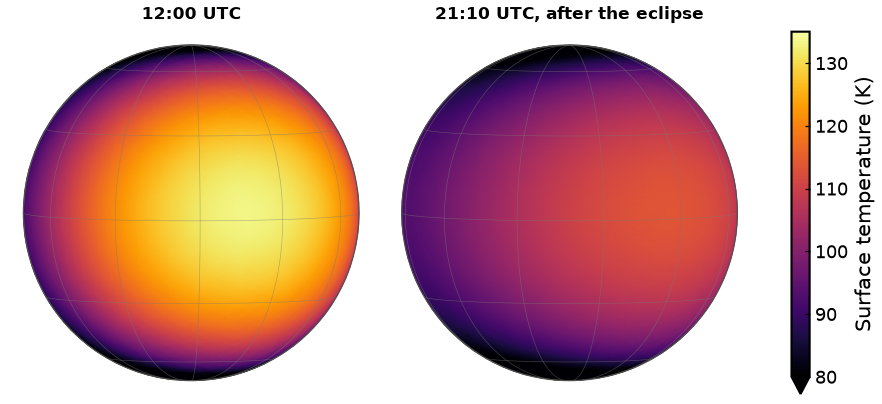

In [4]:
mesh = run.mesh
times = {"2025-01-01T12:00:00": "12:00 UTC", "2025-01-01T21:10:00": "21:10 UTC, after the eclipse"}
geoms = {utc: observe.observer_geometry(run, utc, observer="EARTH") for utc in times}

fig, axes = plt.subplots(1, 2, figsize=(8.0, 4.2), constrained_layout=True)
for ax, (utc, title) in zip(axes, times.items()):
    g = geoms[utc]
    T = observe.temperature_at(run, g)
    tv = plots.vertex_values_from_faces(mesh["faces"], T, mesh["n_vertices"])
    art = plots.globe(ax, mesh["vertices"], mesh["faces"], tv, g.sub_observer_lat,
                      g.sub_observer_lon, norm=plt.Normalize(80, 135), title=title)
fig.colorbar(art, ax=axes, shrink=0.8, extend="min", label="Surface temperature (K)");

The warmest surface is near the center of the disk, because Earth and the Sun are within a few
degrees of each other as seen from Europa. A few minutes after the end of the eclipse the surface
has recovered only part of the cooling.

The same snapshot can be written as a table for use elsewhere. The next cell keeps the faces that
Earth sees and writes their position, the cosine of the emission angle $\mu$ and the surface
temperature.

In [5]:
g = geoms["2025-01-01T12:00:00"]
T = observe.temperature_at(run, g)
disk = observe.disk_mesh(run)
mu = disk.normals @ (g.observer_km / np.linalg.norm(g.observer_km))
visible = mu > 0
table = RUN_DIR / "snapshot_2025-01-01T120000.csv"
with open(table, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["face", "lat_deg", "lon_deg", "mu", "area_m2", "temperature_K"])
    for i in np.flatnonzero(visible):
        w.writerow([i, f"{run.lat[i]:.3f}", f"{run.lon[i]:.3f}", f"{mu[i]:.5f}",
                    f"{run.face_areas_m2[i]:.6g}", f"{T[i]:.3f}"])
print(f"{visible.sum()} of {run.n_faces} faces visible, written to {table.name}")

2560 of 5120 faces visible, written to snapshot_2025-01-01T120000.csv


## 4. Temperature with depth

At millimeter wavelengths water ice is partly transparent, and the emission comes from the upper
several centimeters. `depth_temperatures_at` returns the temperature at every output depth of every
face at the same moment. The profile at the center of the disk shows the diurnal wave near the
surface and the cooling left by the eclipse.

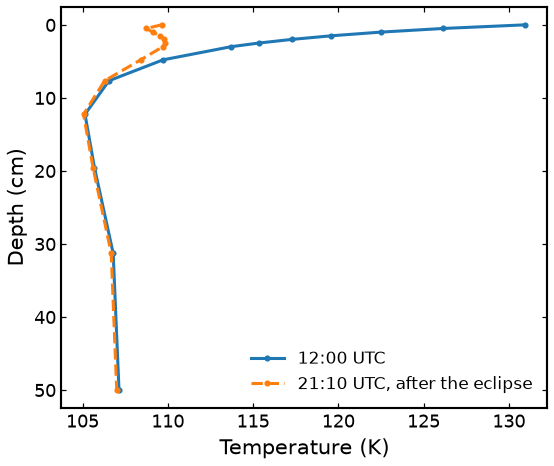

In [6]:
fig, ax = plt.subplots(figsize=(5.0, 4.2), constrained_layout=True)
for (utc, title), style in zip(times.items(), ("-", "--")):
    g = geoms[utc]
    depths, Tz = observe.depth_temperatures_at(run, g)
    center = int(np.argmax(disk.normals @ (g.observer_km / np.linalg.norm(g.observer_km))))
    ax.plot(Tz[center], 100 * depths, style, marker="o", ms=3, label=title)
ax.invert_yaxis()
ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Depth (cm)")
ax.legend(frameon=False, loc="lower right");

## 5. The disk brightness temperature

In the surface mode each face emits as a gray body with a band emissivity $\varepsilon$, and the
flux density at distance $d$ is the sum over the visible faces,

$$F_\nu = \frac{1}{d^2} \sum_i \varepsilon B_\nu(T_i) A_i \mu_i ,$$

where $B_\nu$ is the Planck function, $A_i$ the area of face $i$ and $\mu_i$ the cosine of its
emission angle. The disk brightness temperature $T_\mathrm{b}$ is the temperature of a black disk of
radius $R$ that gives the same flux, $F_\nu = B_\nu(T_\mathrm{b}) \pi R^2 / d^2$.

In the subsurface mode the emission of each face is integrated through its temperature profile
along the ray refracted into the ice, with the electrical skin depth and the Fresnel
transmissivity of a porous-ice dielectric model ([docs/observing.md](../../observing.md)).

In [7]:
sub = observe.Subsurface(porosity=0.5)
for utc, title in times.items():
    g = geoms[utc]
    surface = observe.disk_emission(run, observe.temperature_at(run, g), g,
                                    frequency_ghz=233.0, emissivity=0.9)
    depths, Tz = observe.depth_temperatures_at(run, g)
    subsurface = observe.disk_emission(run, Tz, g, frequency_ghz=233.0,
                                       subsurface=sub, depths_m=depths)
    print(f"{title:28s}  surface mode {surface.tb_planck_k:6.2f} K   "
          f"subsurface mode {subsurface.tb_planck_k:6.2f} K   ({surface.flux_density_jy:.3f} Jy surface)")

12:00 UTC                     surface mode 104.19 K   subsurface mode  98.24 K   (3.193 Jy surface)
21:10 UTC, after the eclipse  surface mode  91.54 K   subsurface mode  94.97 K   (2.780 Jy surface)


These are the numbers that `ptm observe` prints from the command line (tutorial 7). Following the
disk brightness temperature through the orbit shows the eclipse as the strongest signal. The cell
samples it every 30 minutes and leaves a gap while Jupiter hides Europa.

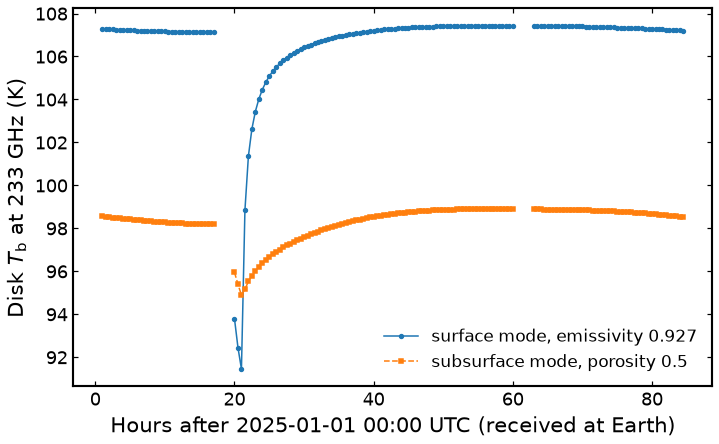

In [8]:
hours, tb_surf, tb_sub = [], [], []
for h in np.arange(1.0, 85.0, 0.5):
    utc = str(np.datetime64("2025-01-01T00:00:00") + np.timedelta64(int(h * 3600), "s"))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        g = observe.observer_geometry(run, utc, observer="EARTH")
    hours.append(h)
    if g.occultation != "visible":              # break the curves while Jupiter hides Europa
        tb_surf.append(np.nan)
        tb_sub.append(np.nan)
        continue
    tb_surf.append(observe.disk_emission(run, observe.temperature_at(run, g), g,
                                         frequency_ghz=233.0, emissivity=0.927).tb_planck_k)
    depths, Tz = observe.depth_temperatures_at(run, g)
    tb_sub.append(observe.disk_emission(run, Tz, g, frequency_ghz=233.0, subsurface=sub,
                                        depths_m=depths).tb_planck_k)

fig, ax = plt.subplots(figsize=(6.5, 4.0), constrained_layout=True)
ax.plot(hours, tb_surf, "o-", ms=2.5, lw=1, label="surface mode, emissivity 0.927")
ax.plot(hours, tb_sub, "s--", ms=2.5, lw=1, label="subsurface mode, porosity 0.5")
ax.set_xlabel("Hours after 2025-01-01 00:00 UTC (received at Earth)")
ax.set_ylabel(r"Disk $T_\mathrm{b}$ at 233 GHz (K)")
ax.legend(frameon=False, loc="lower right");

The emissivity 0.927 is the disk average of the Fresnel transmissivity of the subsurface model, so
the two curves differ only in where the emission comes from. The subsurface brightness
temperature is lower, because the emitting layer lies below the warm daytime surface, and its
eclipse dip is much shallower.

## 6. Output cadence near an eclipse

Linear interpolation between output steps 26.6 minutes apart is adequate for Europa's slow
rotation but not at the edges of the shadow, where the surface warms by several kelvin in a few
minutes. A model used to fit eclipse observations needs output steps of 1 minute or less within
10 minutes of the shadow contacts. The fitting example below therefore adds, for each thermal
inertia, a five-hour run with one-minute steps around the eclipse.

## 7. Fitting thermal inertia and emissivity to synthetic observations

`examples/python/fit_europa_disk_tb.py` runs the simulations of the fit. It runs Europa at seven
thermal inertias from 20 to 240 SI and at a true value of 70, each for one orbit and again around
the eclipse at one-minute steps. It then makes 12 synthetic observations from the true run, with
emissivity 0.85 and 1 percent noise, at six times that follow the rotation and six that follow
Europa out of Jupiter's shadow. Run it once from a terminal at the repository root:

```bash
python3 examples/python/fit_europa_disk_tb.py
```

The cell below stops with a message if those runs are missing. It then repeats the fit here, using
the functions of the script, so that each step can be inspected.

In [9]:
FIT_DIR = ROOT / "output" / "europa_disk_fit"
needed = ["grid_orbit", "grid_eclipse", "truth_orbit", "truth_eclipse", "synthetic_observations.csv"]
missing = [n for n in needed if not (FIT_DIR / n).exists()]
if missing:
    raise RuntimeError(
        "The fit needs the simulations of examples/python/fit_europa_disk_tb.py, which take 4 to 7 "
        "minutes. From the repository root run\n    python3 examples/python/fit_europa_disk_tb.py\n"
        f"and then run this cell again. Missing in output/europa_disk_fit: {', '.join(missing)}")

sys.path.insert(0, str(ROOT / "examples" / "python"))
import fit_europa_disk_tb as fit

sweeps = fit.run_simulations(FIT_DIR, 0, run=False)
model = {}
for kind, (grid, truth) in sweeps.items():
    runs = grid.results()
    ti = np.array(grid.values("constant_thermal_inertia"), dtype=float)
    order = np.argsort(ti)
    model[kind] = [runs[i] for i in order]
TI = ti[order]
flux_rot, geoms_rot, omega_rot = fit.disk_fluxes(model["orbit"], fit.ROTATION_TIMES)
flux_ecl, geoms_ecl, omega_ecl = fit.disk_fluxes(model["eclipse"], fit.ECLIPSE_TIMES)
flux_grid = np.hstack([flux_rot, flux_ecl])          # Jy at emissivity 1, (thermal inertia, time)
omega = np.concatenate([omega_rot, omega_ecl])
print("thermal inertias of the model grid:", TI)
print("model flux densities at emissivity 1 (Jy), first time:", np.round(flux_grid[:, 0], 4))

[sweep] engine <repo>/build/bin/ptm_thermal_sim (md5 0f278820ed46c59ca3043c7fe500999a)
[sweep] axis constant_thermal_inertia: 7 values -> --constant-thermal-inertia (engine advertises it)
[sweep]   note (constant_thermal_inertia): this is cp = TI^2/(ks*rhos) with chi=0, kd=ks and rhod=rhos: TI is exactly constant in temperature AND depth, and the thermal diffusivity therefore varies along the axis. The other convention, thermal_inertia, scales ks/kd instead, giving a measurably different diurnal amplitude on the same config. Choose deliberately.
[sweep] engine <repo>/build/bin/ptm_thermal_sim (md5 0f278820ed46c59ca3043c7fe500999a)
[sweep] axis constant_thermal_inertia: 7 values -> --constant-thermal-inertia (engine advertises it)
[sweep]   note (constant_thermal_inertia): this is cp = TI^2/(ks*rhos) with chi=0, kd=ks and rhod=rhos: TI is exactly constant in temperature AND depth, and the thermal diffusivity therefore varies along the axis. The other convention, thermal_inertia, scales 

thermal inertias of the model grid: [ 20.  35.  50.  85. 120. 170. 240.]
model flux densities at emissivity 1 (Jy), first time: [3.807  3.7268 3.656  3.5411 3.4678 3.4008 3.3446]


The synthetic observations are read from the file the script wrote. To fit real measurements,
replace `obs` and `sigma` with measured flux densities and their uncertainties at the same
observing times.

In [10]:
with open(FIT_DIR / "synthetic_observations.csv") as fh:
    print(fh.readline().strip())                    # the line that records how they were made
    rows = list(csv.DictReader(fh))
obs = np.array([float(r["flux_density_jy"]) for r in rows])
sigma = np.array([float(r["sigma_jy"]) for r in rows])
tb_obs = np.array([float(r["tb_planck_k"]) for r in rows])
kind = np.array([r["set"] for r in rows])
for r in rows[:3]:
    print(r["utc_observed"], r["set"], r["flux_density_jy"], "Jy")

"# SYNTHETIC: constant thermal inertia 70.0, emissivity 0.85, 1 percent noise, seed 20261116"
2025-01-01T08:00:00.000 rotation 3.030608 Jy
2025-01-02T04:00:00.000 rotation 3.010556 Jy
2025-01-02T16:00:00.000 rotation 3.008904 Jy


Emissivity scales the flux exactly, so only thermal inertia needs simulations. The script
interpolates the flux at each time with a cubic spline in $\ln \Gamma$ and evaluates

$$\chi^2(\Gamma, \varepsilon) = \sum_j \left( \frac{\varepsilon F_j(\Gamma) - F_j^\mathrm{obs}}{\sigma_j} \right)^2$$

on a fine grid. The intervals are the ranges where $\chi^2$, minimized over the other parameter,
is within 1 of its minimum.

In [11]:
ti_fine = np.geomspace(TI[0], TI[-1], 400)
eps_fine = np.linspace(0.60, 1.00, 401)
sets = {"rotation only": np.flatnonzero(kind == "rotation"),
        "rotation and eclipse": np.arange(len(obs))}
surfaces, best = {}, {}
for name, idx in sets.items():
    c2 = fit.chi2_surface(np.log(TI), flux_grid[:, idx], obs[idx], sigma[idx], ti_fine, eps_fine)
    surfaces[name] = c2
    e, t = np.unravel_index(np.argmin(c2), c2.shape)
    best[name] = (ti_fine[t], eps_fine[e])
    ti_lo, ti_hi = fit.interval(ti_fine, c2.min(axis=0))
    ep_lo, ep_hi = fit.interval(eps_fine, c2.min(axis=1))
    print(f"{name:22s}: thermal inertia {ti_fine[t]:6.1f} [{ti_lo:.1f}, {ti_hi:.1f}]   "
          f"emissivity {eps_fine[e]:.3f} [{ep_lo:.3f}, {ep_hi:.3f}]   min chi-square {c2.min():.1f}")

rotation only         : thermal inertia   24.1 [20.0, 240.0]   emissivity 0.804 [0.797, 0.909]   min chi-square 0.8
rotation and eclipse  : thermal inertia   66.5 [62.9, 70.4]   emissivity 0.846 [0.844, 0.848]   min chi-square 8.9


These are the values the script prints. The first figure shows the misfit against thermal inertia,
minimized over emissivity at each value, and the second the regions of 68 and 95 percent
confidence for the two parameters together.

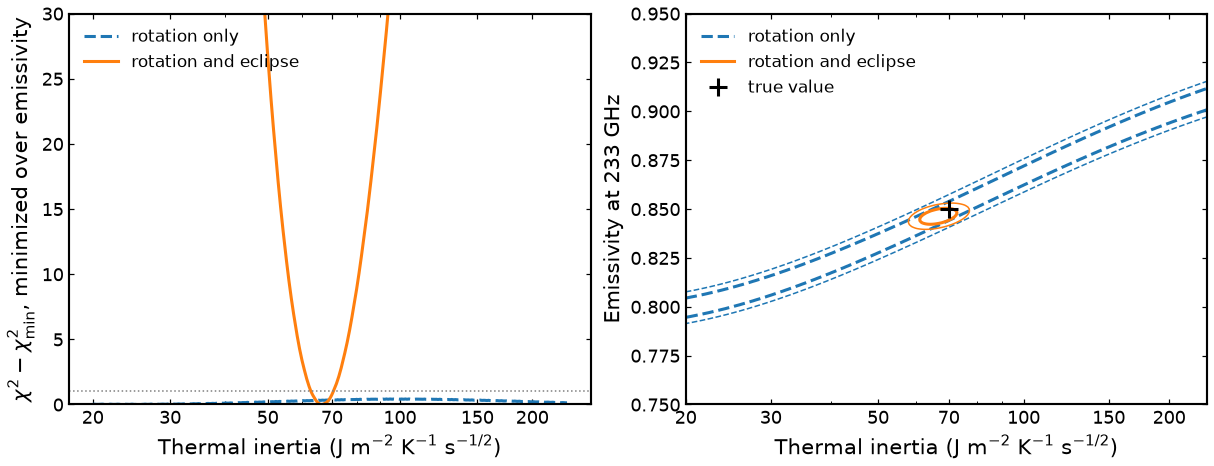

In [12]:
from matplotlib.ticker import NullFormatter, ScalarFormatter

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2), constrained_layout=True)
for (name, c2), style in zip(surfaces.items(), ("--", "-")):
    axes[0].plot(ti_fine, c2.min(axis=0) - c2.min(), style, lw=2, label=name)
    axes[1].contour(ti_fine, eps_fine, c2 - c2.min(), levels=[2.30, 6.18],
                    linestyles=style, linewidths=[2.0, 1.0],
                    colors="C0" if name == "rotation only" else "C1")
    axes[1].plot([], [], style, color="C0" if name == "rotation only" else "C1", lw=2, label=name)
axes[0].axhline(1.0, color="0.5", lw=1, ls=":")
axes[0].set_ylim(0, 30)
axes[0].set_ylabel(r"$\chi^2 - \chi^2_\mathrm{min}$, minimized over emissivity")
axes[1].plot([fit.TRUE_TI], [fit.TRUE_EMISSIVITY], "k+", ms=12, mew=2, label="true value")
axes[1].set_ylim(0.75, 0.95)
axes[1].set_ylabel("Emissivity at 233 GHz")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks([20, 30, 50, 70, 100, 150, 200])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(r"Thermal inertia (J m$^{-2}$ K$^{-1}$ s$^{-1/2}$)")
    ax.legend(frameon=False, loc="upper left");

With the rotation alone the misfit is nearly flat in thermal inertia, because Europa is always
seen near noon and a higher thermal inertia is offset by a higher emissivity. The observations
after the eclipse follow the warming of the surface, whose rate depends on thermal inertia, and
they close the valley around the true values.

The last figure compares the best fit with the observations, as brightness temperatures, and
shows the residuals in units of the uncertainty.

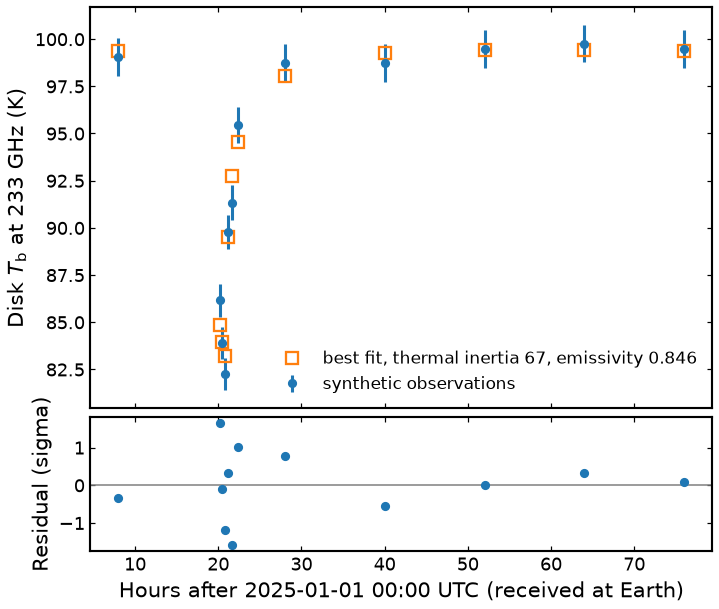

In [13]:
from scipy.interpolate import CubicSpline

ti_best, eps_best = best["rotation and eclipse"]
flux_best = eps_best * np.array([CubicSpline(np.log(TI), flux_grid[:, j])(np.log(ti_best))
                                 for j in range(flux_grid.shape[1])])
nu = 233.0e9
tb_best = observe.planck_nu_temperature(flux_best * observe.JANSKY / omega, nu)
geoms_all = geoms_rot + geoms_ecl
hours_obs = np.array([(np.datetime64(g.utc_observed[:19]) - np.datetime64("2025-01-01T00:00:00"))
                      / np.timedelta64(1, "h") for g in geoms_all])

fig, axes = plt.subplots(2, 1, figsize=(6.5, 5.5), sharex=True, constrained_layout=True,
                         gridspec_kw={"height_ratios": [3, 1]})
axes[0].errorbar(hours_obs, tb_obs, yerr=tb_obs * sigma / obs, fmt="o", ms=5,
                 label="synthetic observations")
axes[0].plot(hours_obs, tb_best, "s", mfc="none", ms=8, mew=1.5,
             label=f"best fit, thermal inertia {ti_best:.0f}, emissivity {eps_best:.3f}")
axes[0].set_ylabel(r"Disk $T_\mathrm{b}$ at 233 GHz (K)")
axes[0].legend(frameon=False, loc="lower right")
axes[1].axhline(0, color="0.5", lw=1)
axes[1].plot(hours_obs, (obs - flux_best) / sigma, "o", ms=5)
axes[1].set_ylabel("Residual (sigma)")
axes[1].set_xlabel("Hours after 2025-01-01 00:00 UTC (received at Earth)");

The residuals scatter by about one standard deviation, as they should for a correct model and
correctly stated uncertainties. A fit to synthetic observations tests the method and the choice of
observing times. It says nothing about Europa's actual properties.

## 8. Exercises

1. Remove the eclipse times one at a time and watch how the interval in thermal inertia grows.
   Which of the six eclipse times carries the most information?
2. Repeat section 5 at 97.5 GHz. The command warns that the depths do not reach seven electrical
   skin depths. Extend `output.map_depths_m` and raise `thermal.thermal_b` in the configuration
   until the warning stops, and compare the eclipse dip at the two frequencies.
3. `examples/python/fit_europa_disk_tb_subsurface.py` fits thermal inertia and the electrical
   skin depth with the subsurface mode at two frequencies (6 to 7 minutes, 2.3 GB of disk). Compare
   its intervals with those above.